----
# Laboratorium 4 - Transmitancja i charakterystyki częstotliwościowe
----
Materiały dydaktyczne przeznaczone są wyłącznie dla studentów wydziału Informatyki i Telekomunikacji Politechniki Poznańskiej  

---- 
## 0. Zagadnienia do opanowania przed zajęciami
---- 
### 0.1. Zapoznanie z postawami biblioteki *sympy*
https://docs.sympy.org/latest/tutorial/index.html
### 0.2. Przydatne informacje:
Funkcje z biblioteki *sympy* potrzebne do zrealizowania ćwiczenia:  
`sympy.Symbol, sympy.I, sympy.re(), sympy.im(), sympy.Abs, sympy.arg`

Dokumentacja i opisy poszczególnych funkcji *sympy*:

- https://docs.sympy.org/latest/tutorial/gotchas.html#symbols  
- https://docs.sympy.org/latest/modules/utilities/lambdify.html
- https://docs.sympy.org/latest/modules/functions/elementary.html



## 🧭 Jak czytać ten notatnik
To Twój notatnik – Twój kod został, ale ma **komentarz przy każdej linijce**. Dopisane: zadanie 4 (`freqs`), zadanie 5 przerobione na `plt` z poprawką, sekcje **📘 Teoria**, **🔧 Składnia**, **💡 Wyjaśnienie** / **✅ Wnioski** oraz **📝 ściąga** na końcu.

---- 
## Transmitancje
---- 

$ H_1(s) = {{s} \over {5s + 1}} $   
$ H_2(s) = {{2} \over {s + 3}} $  
$ H_3(s) = {{s + 2} \over {s + 3}} $  
$ H_4(s) = {{s + 2} \over {s + 1}} $  
$ H_5(s) = {{2s + 3} \over {2s + 4}} $  
$ H_6(s) = {{1} \over {2s^2 + s + 1}} $     

### 📘 Teoria

**Transmitancja operatorowa** $H(s)=\dfrac{Y(s)}{X(s)}$ – stosunek transformaty Laplace'a wyjścia do wejścia układu. Opisuje układ w całości: znając $H(s)$, wiemy jak układ zareaguje na dowolne wejście.

Zapisujemy ją jako iloraz wielomianów:
$$H(s)=\frac{B(s)}{A(s)}\qquad B\text{ – licznik},\ A\text{ – mianownik}$$

**Charakterystyki częstotliwościowe** mówią, co układ robi z **sinusoidą** o pulsacji $\omega$. Dostajemy je, podstawiając $s=j\omega$ (czyli patrzymy na transmitancję na osi urojonej):
$$H(j\omega)=\mathrm{Re}(\omega)+j\,\mathrm{Im}(\omega)=|H(j\omega)|\,e^{j\varphi(\omega)}$$
- **charakterystyka amplitudowa** $|H(j\omega)|=\sqrt{\mathrm{Re}^2+\mathrm{Im}^2}$ – ile razy układ wzmacnia/tłumi sinusoidę o pulsacji $\omega$,
- **charakterystyka fazowa** $\varphi(\omega)=\arg H(j\omega)=\operatorname{atan2}(\mathrm{Im},\mathrm{Re})$ – o ile ją przesuwa w fazie.

Wejście $\sin(\omega t)$ → wyjście $|H(j\omega)|\sin(\omega t+\varphi(\omega))$.

**Współczynniki do numpy/scipy** (od najwyższej potęgi $s$, 0 dla brakujących):

| | $H(s)$ | B | A | typ filtru |
|---|---|---|---|---|
| $H_1$ | $\frac{s}{5s+1}$ | `[1, 0]` | `[5, 1]` | górnoprzepustowy |
| $H_2$ | $\frac{2}{s+3}$ | `[2]` | `[1, 3]` | dolnoprzepustowy |
| $H_3$ | $\frac{s+2}{s+3}$ | `[1, 2]` | `[1, 3]` | „półka”: $\frac23$ → 1 |
| $H_4$ | $\frac{s+2}{s+1}$ | `[1, 2]` | `[1, 1]` | „półka”: 2 → 1 |
| $H_5$ | $\frac{2s+3}{2s+4}$ | `[2, 3]` | `[2, 4]` | „półka”: $\frac34$ → 1 |
| $H_6$ | $\frac{1}{2s^2+s+1}$ | `[1]` | `[2, 1, 1]` | dolnoprzepustowy II rzędu (z rezonansem) |

In [1]:
%matplotlib inline
import sympy                 # obliczenia symboliczne
import numpy as np           # obliczenia numeryczne
import scipy.signal          # funkcje do sygnałów i układów (freqs w zadaniu 4)
import matplotlib.pyplot as plt   # wykresy
default_figsize=(12, 6)      # domyślny rozmiar okna

----
## 1. Charakterystyka amplitudowa i fazowa układu - metoda analityczna
----
### Zadanie: Wyznacz i wyświetl matematyczną postać charakterystyki amplitudowej i fazowej dla układu o podanej transmitancji operatorowej.
Podpowiedź: użyj `sympy.I`, `sympy.re()`, `sympy.im()`  

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `ω = sympy.Symbol('ω', real=True)` | symbol pulsacji; `real=True` jest **ważne** – inaczej sympy nie wie, że ω jest rzeczywiste i nie umie wydzielić części rzeczywistej/urojonej |
| `s = 0 + sympy.I*ω` | podstawienie $s=j\omega$; `sympy.I` to $j$ |
| `sympy.re(H)`, `sympy.im(H)` | część rzeczywista i urojona wyrażenia |
| `sympy.simplify(...)` | uproszczenie |
| `sympy.sqrt(x)` | pierwiastek symboliczny |
| `sympy.atan2(Im, Re)` | kąt wektora (Re, Im) z **poprawną ćwiartką** (wynik w $(-\pi, \pi]$). Zwykłe `atan(Im/Re)` myli ćwiartki, gdy Re < 0 (ważne dla $H_6$) |
| `display('tekst', wyrażenie)` | ładne wyświetlenie |

Zamiast `sqrt(Re²+Im²)` i `atan2` można też użyć `sympy.Abs(H)` i `sympy.arg(H)` (podpowiedź z sekcji 0) – wynik ten sam.

In [2]:
#declare symbolic variable 'ω' (omega)
ω = sympy.Symbol('ω', real = True)      # pulsacja ω – rzeczywista
#declare symbolic variable 's'
s = 0 + sympy.I*ω                        # s = jω → transmitancja widmowa H(jω)

# transmitancja układów

H1 = s/(5*s + 1)                         # H1(s) = s / (5s + 1)
H2 = 2 / (s + 3)                         # H2(s) = 2 / (s + 3)
H3 = (s + 2) / (s + 3)                   # H3(s) = (s + 2) / (s + 3)
H4 = (s + 2) / (s + 1)                   # H4(s) = (s + 2) / (s + 1)
H5 = (2*s + 3) / (2*s + 4)               # H5(s) = (2s + 3) / (2s + 4)
H6 = 1 / (2*s**2 + s + 1)                # H6(s) = 1 / (2s² + s + 1)

H = H1                                   # wybrana transmitancja (zmień na H2..H6, żeby zbadać inne)

# wyznaczenie części rzeczywistej i urojonej transmitancji

Re = sympy.simplify(sympy.re(H))         # Re{H(jω)}
Im = sympy.simplify(sympy.im(H))         # Im{H(jω)}

# wyznaczenie modułu i argumentu transmitancji

M = sympy.simplify(sympy.sqrt(Re**2 + Im**2))   # |H(jω)| = √(Re² + Im²) – charakterystyka amplitudowa
F = sympy.atan2(Im,Re)                          # φ(ω) = atan2(Im, Re) – charakterystyka fazowa

display('Re = ', Re)                     # wyświetlenie wyników
display('Im = ', Im)
display('|H| = ', M)
display('arg H = ', F)

'Re = '

5*ω**2/(25*ω**2 + 1)

'Im = '

ω/(25*ω**2 + 1)

'|H| = '

Abs(ω)/sqrt(25*ω**2 + 1)

'arg H = '

atan2(ω/(25*ω**2 + 1), 5*ω**2/(25*ω**2 + 1))

### 💡 Wyjaśnienie wyniku

Dla $H_1=\frac{j\omega}{5j\omega+1}$ mnożymy licznik i mianownik przez sprzężenie mianownika $(1-5j\omega)$:
$$H_1(j\omega)=\frac{j\omega(1-5j\omega)}{1+25\omega^2}=\frac{5\omega^2}{25\omega^2+1}+j\frac{\omega}{25\omega^2+1}$$
$$|H_1|=\frac{|\omega|}{\sqrt{25\omega^2+1}},\qquad \varphi=\operatorname{atan2}(\omega,\ 5\omega^2)=\frac{\pi}{2}-\arctan(5\omega)$$
To jest dokładnie to, co wypisał sympy.

----
## 2. Charakterystyka amplitudowa i fazowa układu - metoda analityczna - wykres
----
### Zadanie: Sporządzić wykresy wyznaczonych wcześniej charakterystyk amplitudowej i fazowej
Okno wykresu podziel na dwie kolumny, w lewej umieść wykres charakterystyki amplitudowej a prawej wykres charakterystyki fazowej. Dodaj opisy i tytuły. Przyjmij wartości zmiennej 'w' z zakresu od $10^{-2}$ do $10^{2}$).  
Podpowiedź: użyj `numpy.logspace`, `sympy.lambdify`, `matplotlib.axes.Axes.loglog`, `matplotlib.axes.Axes.semilogx`

### 📘 Teoria

Charakterystyki rysujemy w skali **logarytmicznej** po osi $\omega$, bo interesuje nas szeroki zakres częstotliwości ($10^{-2}$ … $10^{2}$ – 4 dekady). W skali liniowej wszystko poniżej 1 byłoby ściśnięte przy zerze.
- amplitudowa: **obie osie log** (`loglog`) – wtedy wiele charakterystyk to proste odcinki (asymptoty Bodego),
- fazowa: tylko oś $\omega$ log (`semilogx`), faza liniowo w radianach.

**Pulsacja graniczna** $H_1$: $\omega_g=\frac{1}{5}=0{,}2$ rad/s – tam $|H|=\frac{1}{5\sqrt2}$ (spadek o 3 dB od wartości $\frac15$), a faza $=\frac{\pi}{4}$.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.logspace(a, b, n)` | n punktów od $10^a$ do $10^b$ **równo rozłożonych w skali log** (tyle samo punktów w każdej dekadzie) – w przeciwieństwie do `linspace` |
| `sympy.lambdify(ω, M, 'numpy')(w)` | wzór → funkcja numpy, od razu wywołana dla całego wektora `w` |
| `plt.subplot(1, 2, 1)` / `(1, 2, 2)` | lewa / prawa połowa okna (1 wiersz, 2 kolumny) |
| `plt.loglog(x, y)` | wykres z obiema osiami logarytmicznymi |
| `plt.semilogx(x, y)` | tylko oś x logarytmiczna |

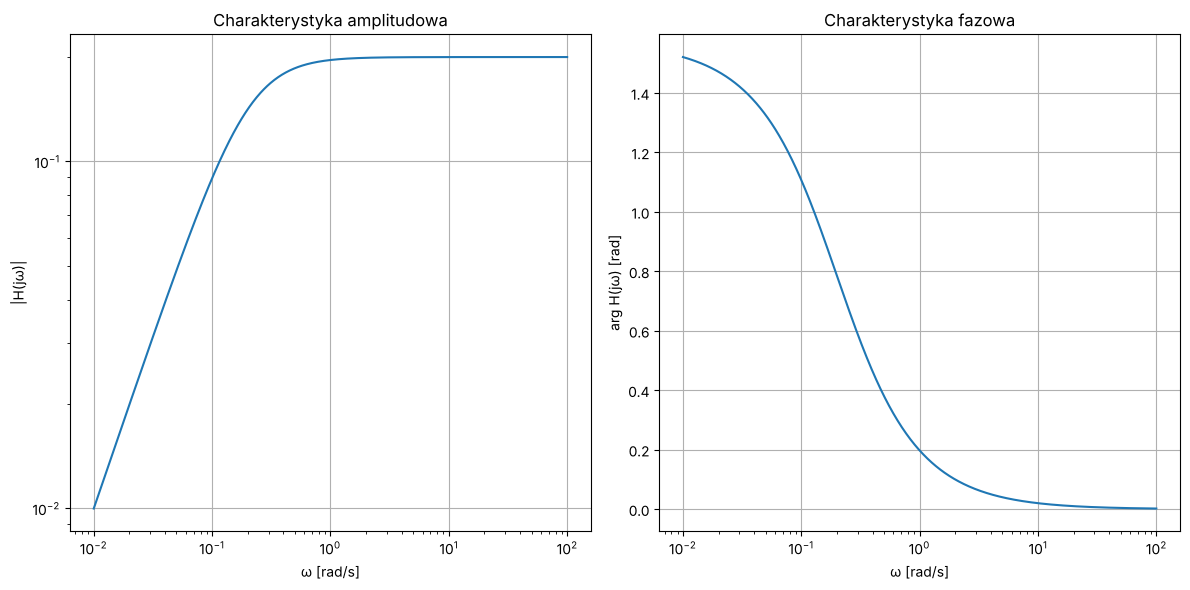

In [3]:
w = np.logspace(-2,2,1000)                    # 1000 pulsacji od 10^-2 do 10^2 (równo w skali log)

Mw = sympy.lambdify(ω,M,'numpy')(w)           # wartości |H(jω)| dla każdego ω
Fw = sympy.lambdify(ω,F,'numpy')(w)           # wartości φ(ω) dla każdego ω

plt.figure(figsize=default_figsize)           # nowe okno

plt.subplot(1,2,1)                            # lewa kolumna – charakterystyka amplitudowa
plt.loglog(w,Mw)                              # obie osie logarytmiczne
plt.title('Charakterystyka amplitudowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('|H(jω)|')
plt.grid()

plt.subplot(1,2,2)                            # prawa kolumna – charakterystyka fazowa
plt.semilogx(w,Fw)                            # oś ω logarytmiczna, faza liniowo
plt.title('Charakterystyka fazowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('arg H(jω) [rad]')
plt.grid()

plt.tight_layout()                            # rozsunięcie wykresów
plt.show()                                    # wyświetlenie

### 💡 Wyjaśnienie wyniku

**$H_1$ to filtr górnoprzepustowy:**
- małe $\omega$: $|H|\approx\omega$ – rośnie (na wykresie log-log prosta o nachyleniu +1, czyli +20 dB/dekadę), faza $\approx\frac\pi2$,
- duże $\omega$: $|H|\to\frac15=0{,}2$ – stała, faza $\to0$,
- przejście w okolicy $\omega=0{,}2$ rad/s.

----
## 3. Charakterystyka amplitudowa i fazowa układu - metoda numeryczna
----
### Zadanie: Sporządzić wykresy charakterystyk amplitudowej i fazowej korzystając jedynie z biblioteki `numpy`
Okno wykresu podziel na dwie kolumny, w lewej umieść wykres charakterystyki amplitudowej a prawej wykres charakterystyki fazowej. Dodaj opisy i tytuły. Przyjmij wartości zmiennej 'w' z zakresu od $10^{-2}$ do $10^{2}$).  
Podpowiedź: $ H(s) = {{B(s)} \over {A(s)}} $
Podpowiedź: wylicz niezależnie wartości dla licznika i mianownika transmitancji  
Podpowiedź: użyj `numpy.logspace`, `numpy.poly1d`, `numpy.abs`, `numpy.angle`, `1j`

### 📘 Teoria

Zamiast wzorów symbolicznych liczymy **bezpośrednio liczby**: dla każdego $\omega$ wstawiamy $s=j\omega$ osobno do licznika i mianownika:
$$H(j\omega)=\frac{B(j\omega)}{A(j\omega)}$$
Numpy umie liczyć na liczbach zespolonych, więc wynik `H` to wektor 1000 liczb zespolonych. Moduł i faza to wtedy po prostu `np.abs(H)` i `np.angle(H)`.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.poly1d([1, 0])` | wielomian $1\cdot s+0=s$ |
| `B(x)` | obiekt `poly1d` **wywołany jak funkcja** liczy wartość wielomianu (działa też dla liczb zespolonych i całych wektorów) |
| `1j` | jednostka urojona $j$ w Pythonie (litera `j` po liczbie) |
| `1j*w` | wektor $j\omega$ dla wszystkich pulsacji |
| `np.abs(H)` | moduł liczby zespolonej $\sqrt{\mathrm{Re}^2+\mathrm{Im}^2}$ |
| `np.angle(H)` | faza (argument) w radianach, zakres $(-\pi,\pi]$ |

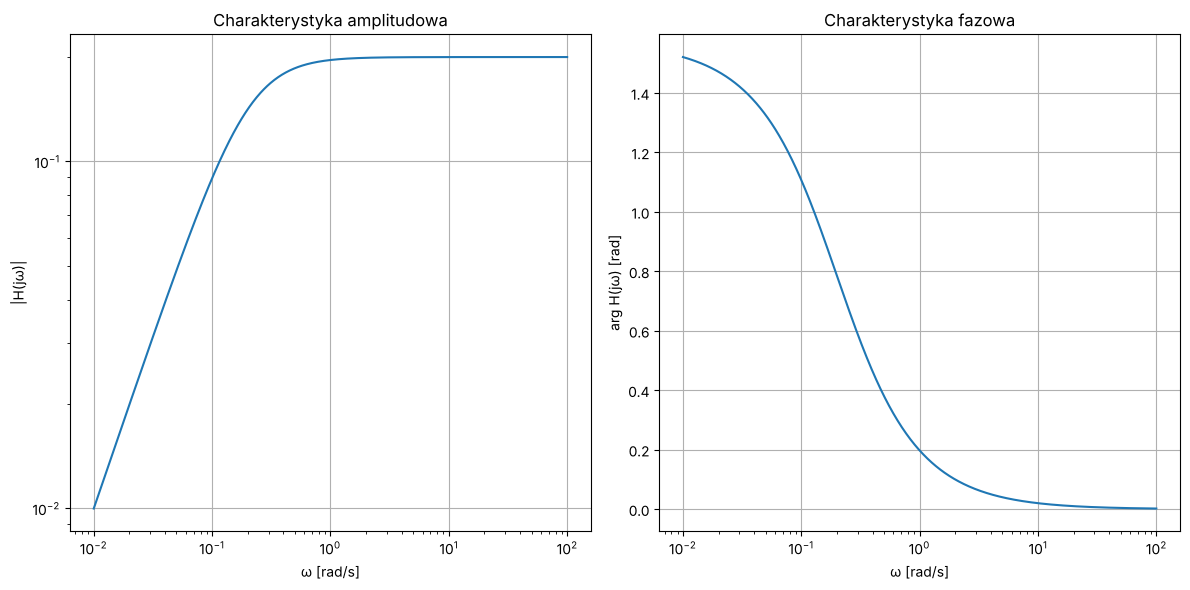

max różnica z metodą analityczną: 8.326672684688674e-17


In [4]:
w = np.logspace(-2,2,1000)                 # pulsacje 10^-2 … 10^2
B = np.poly1d([1,0])                       # licznik:   B(s) = s
A = np.poly1d([5,1])                       # mianownik: A(s) = 5s + 1

H = B(1j*w) / A(1j*w)                      # H(jω) = B(jω) / A(jω) – wektor liczb zespolonych

plt.figure(figsize=default_figsize)

plt.subplot(1,2,1)                         # lewa – amplitudowa
plt.loglog(w,np.abs(H))                    # |H(jω)|
plt.title('Charakterystyka amplitudowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('|H(jω)|')
plt.grid()

plt.subplot(1,2,2)                         # prawa – fazowa
plt.semilogx(w,np.angle(H))                # arg H(jω)
plt.title('Charakterystyka fazowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('arg H(jω) [rad]')
plt.grid()

plt.tight_layout()
plt.show()

print('max różnica z metodą analityczną:', np.max(np.abs(np.abs(H) - Mw)))   # kontrola: powinno być ≈ 0

### 💡 Wyjaśnienie wyniku

Wykresy są identyczne jak w zadaniu 2 (różnica ≈ $10^{-16}$). Metoda numeryczna jest prostsza i szybsza – nie potrzebuje wzorów, tylko współczynniki wielomianów.

----
## 4. Charakterystyka amplitudowa i fazowa układu - metoda numeryczna z użyciem funkcji `freqs` z biblioteki `scipy`
----
Okno wykresu podziel na dwie kolumny, w lewej umieść wykres charakterystyki amplitudowej a prawej wykres charakterystyki fazowej. Dodaj opisy i tytuły. Przyjmij wartości zmiennej 'w' z zakresu od $10^{-2}$ do $10^{2}$).  
Podpowiedź: użyj funkcji `scipy.signal.freqs` do wyliczenia wartości transmitancji. 

### 🔧 Składnia – użyte funkcje

**`w, H = scipy.signal.freqs(b, a, worN=w)`** – liczy odpowiedź częstotliwościową układu **analogowego** (ciągłego):
- `b` – współczynniki licznika (lista, od najwyższej potęgi), np. `[1, 0]`,
- `a` – współczynniki mianownika, np. `[5, 1]`,
- `worN` – wektor pulsacji, dla których liczymy (jak go nie podamy, scipy sam dobierze 200 punktów),
- **zwraca dwie rzeczy**: wektor pulsacji `w` i wektor zespolonych wartości `H(jω)`.

Robi dokładnie to, co my ręcznie w zadaniu 3. (Uwaga: `freqs` – z „s” – jest dla układów ciągłych; `freqz` – z „z” – dla cyfrowych.)

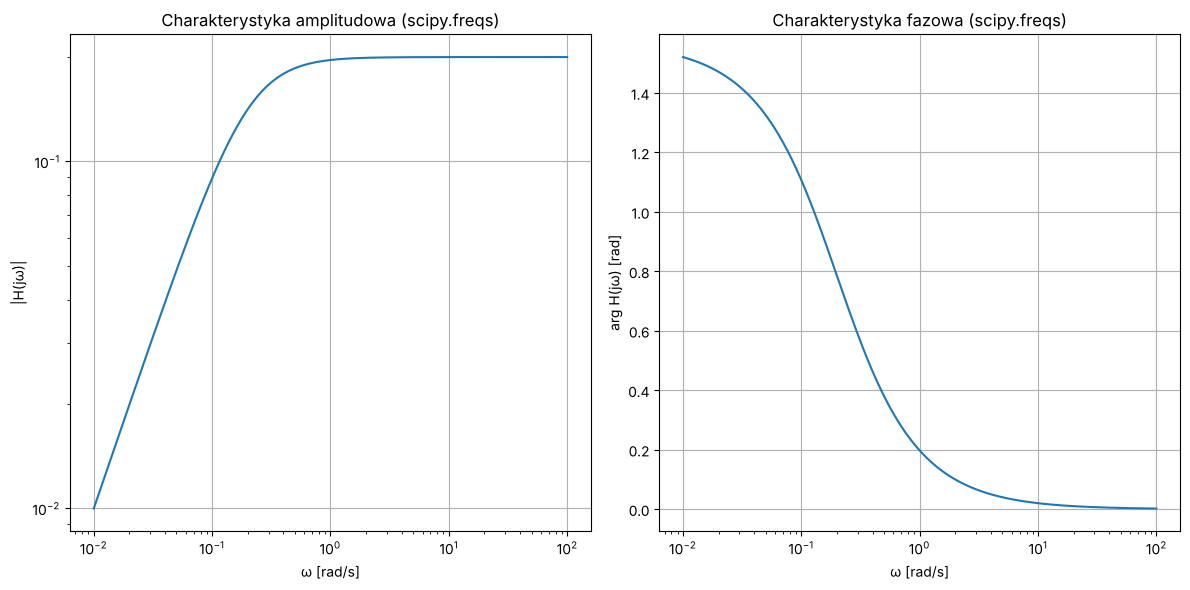

In [5]:
w = np.logspace(-2, 2, 1000)                          # pulsacje 10^-2 … 10^2
w, H = scipy.signal.freqs([1, 0], [5, 1], worN=w)     # licznik s, mianownik 5s+1 → (pulsacje, H(jω))

plt.figure(figsize=default_figsize)

plt.subplot(1, 2, 1)                                  # lewa – amplitudowa
plt.loglog(w, np.abs(H))                              # |H(jω)|
plt.title('Charakterystyka amplitudowa (scipy.freqs)')
plt.xlabel('ω [rad/s]')
plt.ylabel('|H(jω)|')
plt.grid()

plt.subplot(1, 2, 2)                                  # prawa – fazowa
plt.semilogx(w, np.angle(H))                          # arg H(jω)
plt.title('Charakterystyka fazowa (scipy.freqs)')
plt.xlabel('ω [rad/s]')
plt.ylabel('arg H(jω) [rad]')
plt.grid()

plt.tight_layout()
plt.show()

**Wszystkie 6 transmitancji naraz** (komórka dodana) – dzięki `freqs` wystarczy podać współczynniki z tabelki na górze:

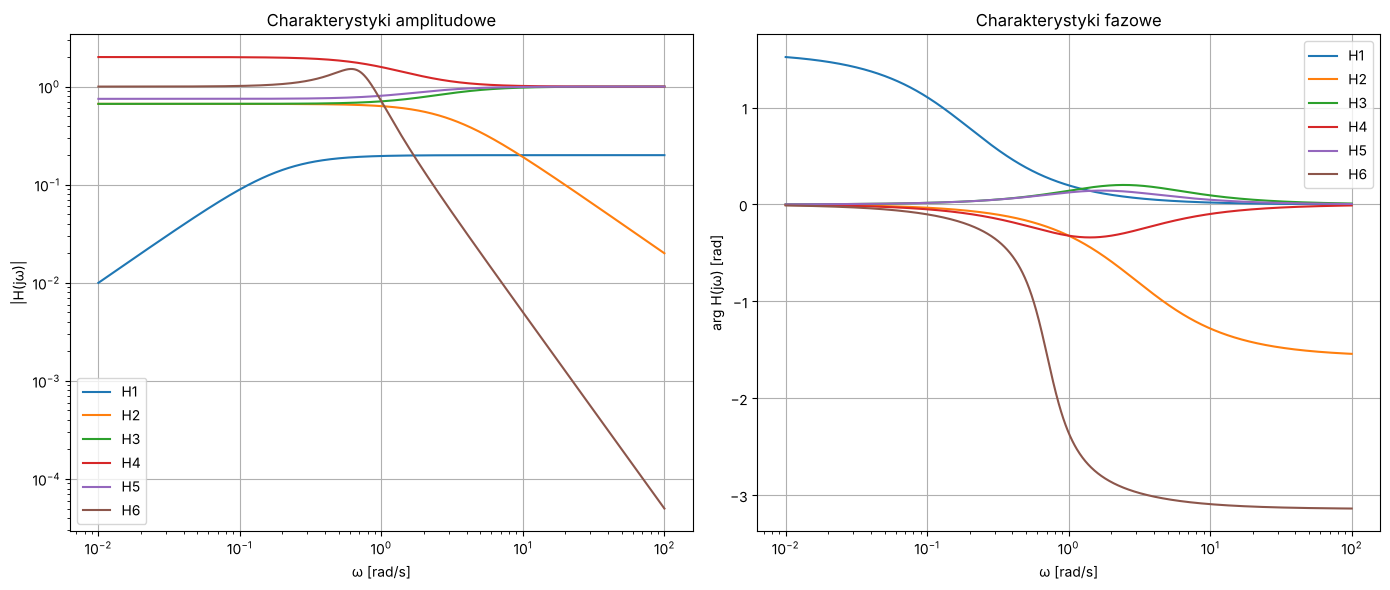

In [6]:
Uklady = { 'H1': ([1, 0], [5, 1]),            # nazwa → (licznik, mianownik)
           'H2': ([2],    [1, 3]),
           'H3': ([1, 2], [1, 3]),
           'H4': ([1, 2], [1, 1]),
           'H5': ([2, 3], [2, 4]),
           'H6': ([1],    [2, 1, 1]) }

w = np.logspace(-2, 2, 1000)
plt.figure(figsize=(14, 6))
for nazwa, (b, a) in Uklady.items():          # rozpakowanie krotki (licznik, mianownik)
    w, H = scipy.signal.freqs(b, a, worN=w)
    plt.subplot(1, 2, 1)                      # wracamy do lewego pola
    plt.loglog(w, np.abs(H), label=nazwa)
    plt.subplot(1, 2, 2)                      # i do prawego
    plt.semilogx(w, np.angle(H), label=nazwa)

plt.subplot(1, 2, 1)
plt.title('Charakterystyki amplitudowe')
plt.xlabel('ω [rad/s]')
plt.ylabel('|H(jω)|')
plt.legend()
plt.grid()
plt.subplot(1, 2, 2)
plt.title('Charakterystyki fazowe')
plt.xlabel('ω [rad/s]')
plt.ylabel('arg H(jω) [rad]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

Wartości graniczne łatwo sprawdzić z wzoru: dla $\omega\to0$ wstawiamy $s=0$, dla $\omega\to\infty$ bierzemy stosunek najwyższych potęg.

| | $\omega\to0$ | $\omega\to\infty$ | charakter |
|---|---|---|---|
| $H_1$ | $0$ | $\frac15$ | **górnoprzepustowy** |
| $H_2$ | $\frac23$ | $0$ | **dolnoprzepustowy**, $\omega_g=3$ |
| $H_3$ | $\frac23$ | $1$ | przepuszcza wszystko, lekko tłumi niskie |
| $H_4$ | $2$ | $1$ | przepuszcza wszystko, wzmacnia niskie |
| $H_5$ | $\frac34$ | $1$ | przepuszcza wszystko, lekko tłumi niskie |
| $H_6$ | $1$ | $0$ (szybko: $\sim\frac{1}{\omega^2}$) | **dolnoprzepustowy II rzędu**, z garbem rezonansowym przy $\omega\approx0{,}6$ (maks. $|H|\approx1{,}5$) |

Układy, w których licznik i mianownik są tego samego stopnia ($H_3$–$H_5$), nie odcinają żadnego pasma – zmieniają tylko poziom między niskimi a wysokimi częstotliwościami.

---- 
## 5. Charakterystyka amplitudowo-fazowa układu
---- 
### Zadanie: Wyznacz część rzeczywistą oraz część urojoną transmitancji układu. Sporządzić wykres charakterystyki amplitudowo-fazowej dla układu o zadanej transmitancji.
Przyjmij wartości zmiennej 'w' z zakresu od $10^{-2}$ do $10^{2}$).  
Podpowiedź: użyj `numpy.real()`, `numpy.imag()`

### 📘 Teoria

**Charakterystyka amplitudowo-fazowa (wykres Nyquista)** łączy obie poprzednie na jednym rysunku: dla każdego $\omega$ rysujemy punkt $H(j\omega)$ na **płaszczyźnie zespolonej**:
- oś x: $\mathrm{Re}\,H(j\omega)$,
- oś y: $\mathrm{Im}\,H(j\omega)$.

**Odległość punktu od (0,0)** to amplituda $|H|$, a **kąt** to faza $\varphi$. Gdy $\omega$ rośnie, punkt „jedzie” po krzywej. Samej osi $\omega$ na tym wykresie nie widać.

Dla $H_1=\frac{s}{5s+1}$ krzywa to **półokrąg** o środku $(0{,}1;\ 0)$ i promieniu $0{,}1$: od punktu $(0,0)$ dla $\omega\to0$ do $(0{,}2;\ 0)$ dla $\omega\to\infty$.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.real(H)` / `H.real` | część rzeczywista każdego elementu |
| `np.imag(H)` / `H.imag` | część urojona |
| `plt.plot(R, I)` | krzywa przez punkty (Re, Im) |
| `plt.axis('equal')` | ta sama skala na obu osiach – okrąg wygląda jak okrąg, a nie elipsa |
| `plt.plot(R[0], I[0], 'go')` | zielona kropka w punkcie startowym (najmniejsze ω) |

### 🛠 Poprawki
1. W kodzie prowadzącego było `B = np.poly1d([1])`, czyli rysował się $\frac{1}{5s+1}$, a **nie** $H_1=\frac{s}{5s+1}$. Licznik $H_1$ to $s$, więc `B = np.poly1d([1, 0])`.
2. Przerobione z `fig, ax` na `plt`.

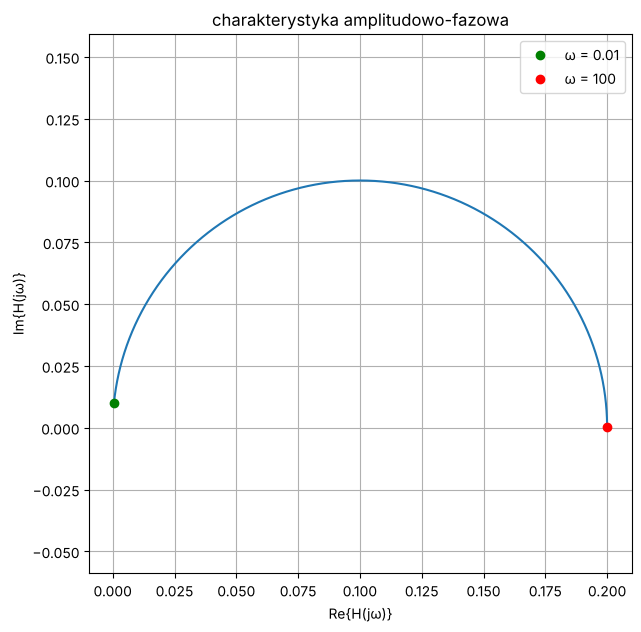

In [7]:
w = np.logspace(-2, 2, 10000)     # pulsacje 10^-2 … 10^2 (dużo punktów → gładka krzywa)
B = np.poly1d([1, 0])             # licznik H1:   s        (POPRAWIONE: było [1])
A = np.poly1d([5, 1])             # mianownik H1: 5s + 1
s = w * 1j                        # s = jω
H = B(s) / A(s)                   # H(jω)
R = np.real(H)                    # część rzeczywista
I = np.imag(H)                    # część urojona

plt.figure(figsize=(7, 7))
plt.plot(R, I)                                    # krzywa Nyquista
plt.plot(R[0], I[0], 'go', label='ω = 0.01')      # początek krzywej
plt.plot(R[-1], I[-1], 'ro', label='ω = 100')     # koniec krzywej ([-1] = ostatni element)
plt.title("charakterystyka amplitudowo-fazowa")
plt.xlabel("Re{H(jω)}")
plt.ylabel("Im{H(jω)}")
plt.axis('equal')                                 # równa skala osi
plt.legend()
plt.grid()
plt.show()

**Wszystkie 6 transmitancji** (komórka dodana):

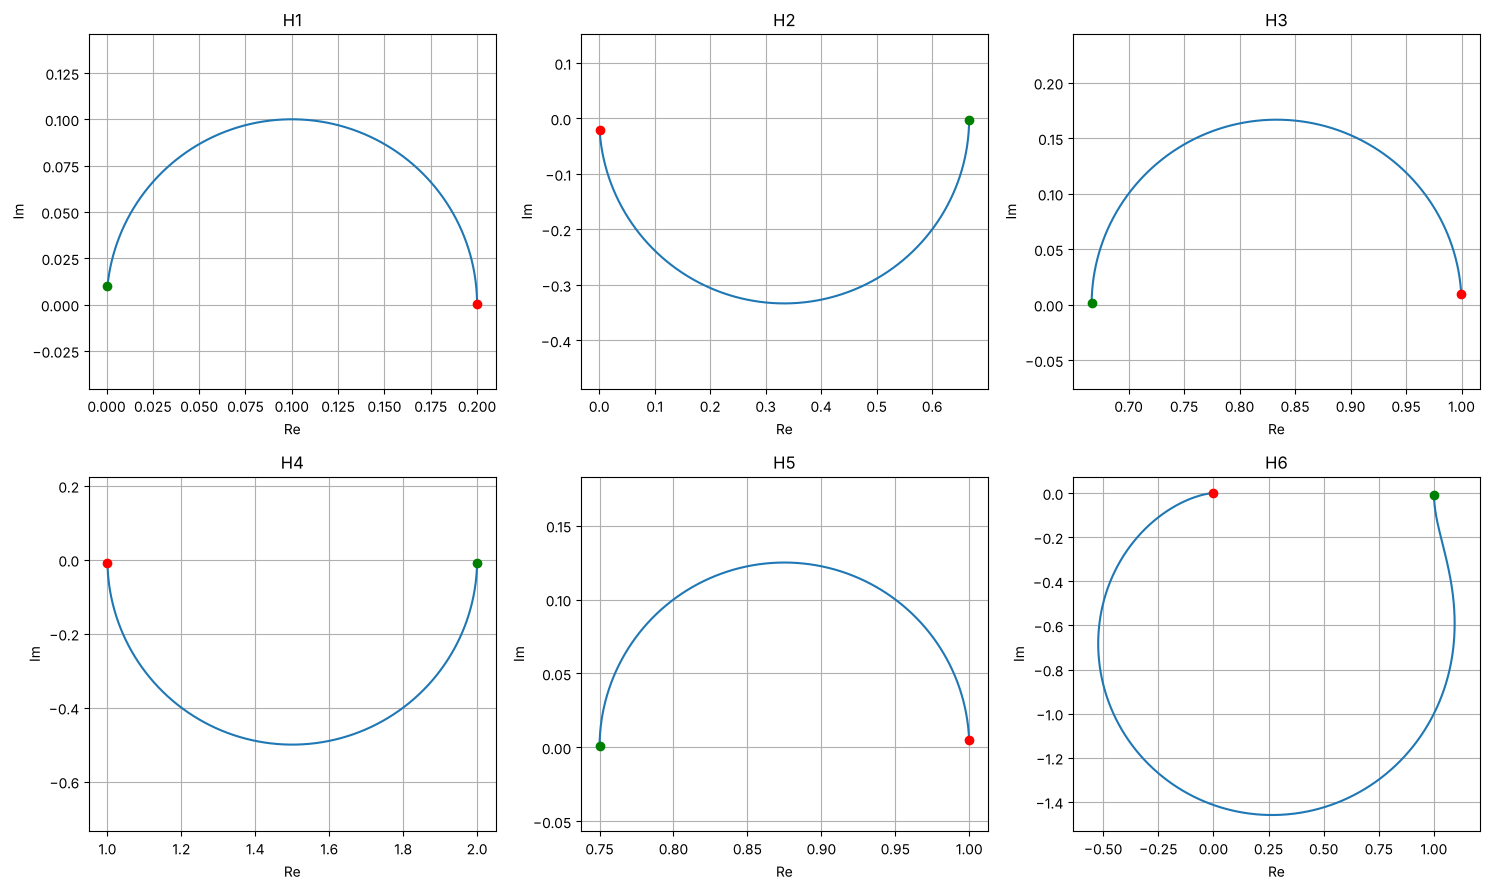

In [8]:
w = np.logspace(-2, 2, 10000)
plt.figure(figsize=(15, 9))
for i, (nazwa, (b, a)) in enumerate(Uklady.items()):    # i – numer pola, nazwa, (licznik, mianownik)
    H = np.poly1d(b)(1j*w) / np.poly1d(a)(1j*w)          # H(jω)
    plt.subplot(2, 3, i + 1)
    plt.plot(H.real, H.imag)
    plt.plot(H.real[0], H.imag[0], 'go')                 # start (małe ω)
    plt.plot(H.real[-1], H.imag[-1], 'ro')               # koniec (duże ω)
    plt.title(nazwa)
    plt.xlabel('Re')
    plt.ylabel('Im')
    plt.axis('equal')
    plt.grid()
plt.tight_layout()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

- **$H_1$:** półokrąg w górnej półpłaszczyźnie od $0$ (zielony) do $0{,}2$ (czerwony) – faza dodatnia (od $\frac\pi2$ do 0), amplituda rośnie: górnoprzepustowy.
- **$H_2$:** półokrąg w **dolnej** półpłaszczyźnie od $\frac23$ do 0 – faza ujemna (od 0 do $-\frac\pi2$), amplituda maleje: dolnoprzepustowy.
- **$H_3$, $H_5$:** małe półokręgi w górnej półpłaszczyźnie, z $\frac23$ / $\frac34$ do 1.
- **$H_4$:** półokrąg w dolnej półpłaszczyźnie z 2 do 1.
- **$H_6$:** krzywa przechodzi przez dwie ćwiartki (faza od 0 do $-\pi$) i kończy w 0 – układ II rzędu.

Czerwona kropka (duże $\omega$) mówi, ile wynosi wzmocnienie dla wysokich częstotliwości, a zielona – dla niskich.

---
# 🎓 Kolokwium – przykładowe pytania z rozwiązaniami
Pytania oznaczone **[z kolokwium]** to prawdziwe przykłady od prowadzącego, pozostałe są **wymyślone w tym samym stylu**. Przy każdym:
- **Odpowiedź (do wpisania)** – krótki tekst, który można wpisać w pole odpowiedzi,
- **Jak to rozwiązać** – kroki, żeby umieć zrobić podobne zadanie samemu,
- kod tam, gdzie zadanie wymaga obliczeń lub wykresu (na kolokwium można dołączyć zrzut wykresu jako obrazek).

### Pytanie 1 [z kolokwium]
**Dla układu LTI o transmitancji $H(s)$ można wyznaczyć jego charakterystyki fazową i amplitudową. Czym jest charakterystyka amplitudowa dla układu LTI? Wyjaśnij krótko na podstawie transmitancji.**

**Odpowiedź (do wpisania):**
Charakterystyka amplitudowa to **moduł transmitancji widmowej** $|H(j\omega)|$, czyli transmitancji operatorowej $H(s)$ po podstawieniu $s=j\omega$. Pokazuje, ile razy układ **wzmacnia lub tłumi amplitudę** sygnału sinusoidalnego o pulsacji $\omega$: jeśli na wejście podamy $\sin(\omega t)$, na wyjściu (w stanie ustalonym) dostaniemy $|H(j\omega)|\sin(\omega t+\varphi(\omega))$. Dla $H(s)=\frac{B(s)}{A(s)}$:
$$|H(j\omega)|=\frac{|B(j\omega)|}{|A(j\omega)|}=\sqrt{\mathrm{Re}^2H(j\omega)+\mathrm{Im}^2H(j\omega)}$$
Na jej podstawie określa się typ filtru (dolno-, górno-, pasmowoprzepustowy). Zwykle rysuje się ją w skali logarytmicznej.

### Pytanie 2 [z kolokwium]
**Wyznacz charakterystyki amplitudową i fazową dla podanej transmitancji. Podaj wzory na wielomiany $A(s)$ i $B(s)$. Określ typ charakterystyki dla tego układu.**
$$H(s)=\frac{s^2+2s+1}{s^4+1}$$

**Jak to rozwiązać:**
1. $B(s)$ = licznik, $A(s)$ = mianownik → współczynniki od najwyższej potęgi, **zera dla brakujących potęg**.
2. Podstaw $s=j\omega$, policz moduł i fazę (ręcznie albo kodem z zadania 3/4).
3. Typ: sprawdź $|H|$ dla $\omega\to0$ i $\omega\to\infty$.

**Odpowiedź (do wpisania):**
- $B(s)=s^2+2s+1=(s+1)^2$ → `B = [1, 2, 1]`
- $A(s)=s^4+1$ → `A = [1, 0, 0, 0, 1]`
- Po podstawieniu $s=j\omega$: $B(j\omega)=(1+j\omega)^2$, $A(j\omega)=\omega^4+1$ (liczba rzeczywista dodatnia), więc
$$|H(j\omega)|=\frac{1+\omega^2}{1+\omega^4},\qquad \varphi(\omega)=\arg B-\arg A=2\arctan\omega$$
- $\omega\to0$: $|H|\to1$; $\ \omega\to\infty$: $|H|\approx\frac{1}{\omega^2}\to0$ (spadek 40 dB/dek); niewielkie maksimum $\approx1{,}21$ przy $\omega\approx0{,}64$. Faza rośnie od 0 do $\pi$.
- **Typ: charakterystyka dolnoprzepustowa** (przepuszcza niskie częstotliwości, tłumi wysokie).

*(Uwaga dodatkowa: mianownik $s^4+1$ ma pierwiastki $\pm\frac{\sqrt2}{2}\pm j\frac{\sqrt2}{2}$ – dwa w prawej półpłaszczyźnie, więc sam układ nie jest stabilny; charakterystykę liczymy formalnie ze wzoru.)*

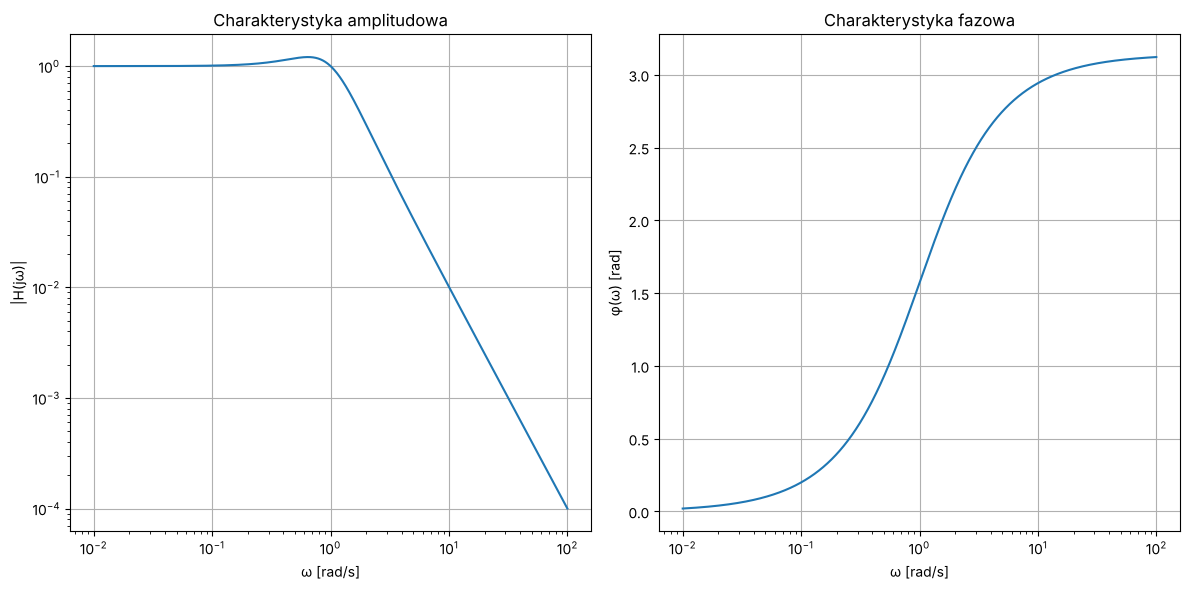

|H| dla ω=0.01: 1.0000999899990002   dla ω=100: 0.0001000099989999   max: 1.2071064605802295
bieguny: [-0.707+0.707j -0.707-0.707j  0.707+0.707j  0.707-0.707j]


In [9]:
B = [1, 2, 1]                           # B(s) = s² + 2s + 1
A = [1, 0, 0, 0, 1]                     # A(s) = s⁴ + 1   (zera dla s³, s², s¹)
w = np.logspace(-2, 2, 2000)
w, H = scipy.signal.freqs(B, A, worN=w)

plt.figure(figsize=default_figsize)
plt.subplot(1, 2, 1)
plt.loglog(w, np.abs(H))
plt.title('Charakterystyka amplitudowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('|H(jω)|')
plt.grid()
plt.subplot(1, 2, 2)
plt.semilogx(w, np.unwrap(np.angle(H)))   # unwrap – usuwa sztuczne skoki fazy o 2π
plt.title('Charakterystyka fazowa')
plt.xlabel('ω [rad/s]')
plt.ylabel('φ(ω) [rad]')
plt.grid()
plt.tight_layout()
plt.show()

print('|H| dla ω=0.01:', abs(H[0]), '  dla ω=100:', abs(H[-1]), '  max:', np.max(abs(H)))
print('bieguny:', np.round(np.roots(A), 3))

### Pytanie 3
Wyznacz charakterystykę amplitudową i fazową układu $H(s)=\dfrac{10}{s+10}$. Podaj typ filtru i pulsację graniczną.

**Jak to rozwiązać:** $H(j\omega)=\frac{10}{10+j\omega}$ → moduł = moduł licznika / moduł mianownika; faza = faza licznika − faza mianownika.

**Odpowiedź (do wpisania):** $B(s)=10$, $A(s)=s+10$.
$$|H(j\omega)|=\frac{10}{\sqrt{100+\omega^2}},\qquad \varphi(\omega)=-\arctan\frac{\omega}{10}$$
$\omega\to0$: $|H|=1$, $\ \omega\to\infty$: $|H|\to0$ → **dolnoprzepustowy**. Pulsacja graniczna $\omega_g=10$ rad/s ($|H|=\frac{1}{\sqrt2}$, $\varphi=-\frac\pi4$).

### Pytanie 4
Określ typ charakterystyki układu $H(s)=\dfrac{s^2}{s^2+s+1}$. Podaj $A(s)$ i $B(s)$.

**Odpowiedź (do wpisania):** $B(s)=s^2$ → `[1, 0, 0]`, $A(s)=s^2+s+1$ → `[1, 1, 1]`.
$$|H(j\omega)|=\frac{\omega^2}{\sqrt{(1-\omega^2)^2+\omega^2}}$$
$\omega\to0$: $|H|\approx\omega^2\to0$; $\ \omega\to\infty$: $|H|\to1$ → **górnoprzepustowy** II rzędu (lekki garb ≈1,15 w okolicy $\omega\approx1{,}4$).

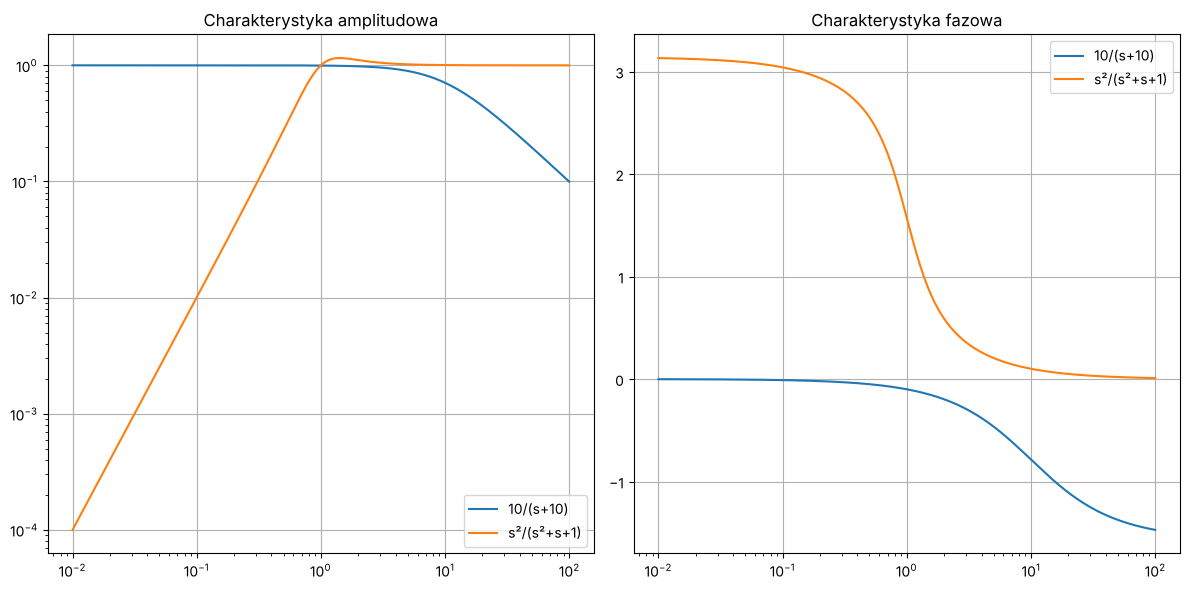

In [10]:
w = np.logspace(-2, 2, 2000)
plt.figure(figsize=default_figsize)
for b, a, nazwa in [([10], [1, 10], '10/(s+10)'), ([1, 0, 0], [1, 1, 1], 's²/(s²+s+1)')]:
    w, H = scipy.signal.freqs(b, a, worN=w)
    plt.subplot(1, 2, 1)
    plt.loglog(w, np.abs(H), label=nazwa)
    plt.subplot(1, 2, 2)
    plt.semilogx(w, np.angle(H), label=nazwa)
plt.subplot(1, 2, 1)
plt.title('Charakterystyka amplitudowa')
plt.legend()
plt.grid()
plt.subplot(1, 2, 2)
plt.title('Charakterystyka fazowa')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Pytanie 5 (teoria)
Czym jest charakterystyka fazowa? Czym jest charakterystyka amplitudowo-fazowa (wykres Nyquista)?

**Odpowiedź (do wpisania):** charakterystyka fazowa to argument transmitancji widmowej $\varphi(\omega)=\arg H(j\omega)$ – mówi, o jaki kąt układ przesuwa w fazie sinusoidę o pulsacji $\omega$. Charakterystyka amplitudowo-fazowa to krzywa, którą zakreśla punkt $H(j\omega)$ na płaszczyźnie zespolonej (oś x: $\mathrm{Re}\,H$, oś y: $\mathrm{Im}\,H$) przy zmianie $\omega$ od 0 do $\infty$; odległość punktu od początku układu to $|H|$, a kąt to $\varphi$.

### Pytanie 6
Wykres Nyquista zaczyna się w punkcie $(0, 0)$ dla małych $\omega$ i kończy w $(1, 0)$ dla dużych $\omega$. Jaki to filtr?

**Odpowiedź (do wpisania):** **górnoprzepustowy** – dla niskich częstotliwości $|H|=0$ (punkt w początku układu), dla wysokich $|H|=1$.

---
## 📝 Ściąga – Laboratorium 4

**Wzory**
$$H(s)=\frac{B(s)}{A(s)},\qquad s=j\omega,\qquad |H(j\omega)|=\sqrt{\mathrm{Re}^2+\mathrm{Im}^2},\qquad \varphi=\operatorname{atan2}(\mathrm{Im},\mathrm{Re})$$
Wejście $\sin\omega t$ → wyjście $|H(j\omega)|\sin(\omega t+\varphi)$. $\ \omega\to0$: podstaw $s=0$; $\ \omega\to\infty$: stosunek najwyższych potęg.

**Trzy metody na charakterystyki**
| metoda | kod |
|---|---|
| symbolicznie | `ω = Symbol('ω', real=True); s = I*ω; M = sqrt(re(H)**2 + im(H)**2); F = atan2(im(H), re(H))` |
| numpy | `H = np.poly1d(b)(1j*w) / np.poly1d(a)(1j*w)` |
| scipy | `w, H = scipy.signal.freqs(b, a, worN=w)` |

**Wykresy**
| | |
|---|---|
| `np.logspace(-2, 2, n)` | pulsacje równo w skali log |
| `plt.loglog(w, np.abs(H))` | amplitudowa |
| `plt.semilogx(w, np.angle(H))` | fazowa |
| `plt.plot(H.real, H.imag); plt.axis('equal')` | Nyquist |
| `plt.subplot(1, 2, 1)` / `(1, 2, 2)` | lewa / prawa kolumna |

**Współczynniki:** od najwyższej potęgi, zero dla brakującej: $s$ → `[1, 0]`, $2s^2+s+1$ → `[2, 1, 1]`.